# Random forest: predicting whether adolescents cross the BDI-II threshold

**Research question:** what factors can predict whether or not adolescents cross the clinical threshold for depression according to the BDI-II?

This notebook applies the Week 8 ensemble material (`01_week8_EnsembleMethods_Forest.ipynb`) to the project data. It uses the same target, features and train/test split as `logistic_regression.ipynb`, `knn.ipynb` and `decision_tree.ipynb`, so the results can be compared directly.

A **random forest** builds many decision trees and lets them vote:
1. **Bootstrap samples:** each tree is trained on its own sample drawn from the training data *with replacement*.
2. **Random feature subsets:** at every split, a tree may only choose from a random subset of the features.
3. **Voting:** each tree predicts, and the forest takes the majority.

**Learning goals (from Week 8), applied here**
- Train a random forest and see how individual trees disagree.
- Evaluate the forest with 5-fold cross-validation.
- See how the number of trees affects performance.
- Inspect which features the forest relies on.
- Evaluate the final model once on the held-out test set.

---
## Step 1. Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
)

# Fixing the random seed makes the split, the bootstrap samples and the folds reproducible
RANDOM_STATE = 42

---
## Step 2. Load data, define target and features

The target is `depressed` (1 if the BDI-II total is 14 or above, 0 if below). The seven features are the same as in the other model notebooks.

In [2]:
df = pd.read_csv("../data/processed/model_ready.csv")

feature_cols = [
    "screen_time_index", "est_leisure_screen_hours", "sex_binary",
    "sleep_quality_index", "avg_sleep_hours",
    "midsleep_weekend_hours", "social_jetlag_hours",
]
target = "depressed"   # 1 = BDI-II total >= 14, 0 = below

X = df[feature_cols]
y = df[target].astype(int)

print("X shape:", X.shape)
print(y.value_counts().rename({0: "not depressed", 1: "depressed"}))
print()
print(y.value_counts(normalize=True).rename({0: "not depressed", 1: "depressed"}).round(3))

X shape: (4810, 7)
depressed
not depressed    4023
depressed         787
Name: count, dtype: int64

depressed
not depressed    0.836
depressed        0.164
Name: proportion, dtype: float64


---
## Step 3. Train/test split

Same settings as the other model notebooks (20% test, seed 42), so the test set is the same 962 adolescents. It is not used until Step 9. All other evaluation uses cross-validation on the training set.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

baseline_acc = (y_test == 0).mean()
print("Training rows:", len(X_train), "| Test rows (kept aside):", len(X_test))
print(f"Depressed in training set: {y_train.mean():.1%}")
print(f"Test baseline (always 'not depressed'): {baseline_acc:.1%}")

Training rows: 3848 | Test rows (kept aside): 962
Depressed in training set: 16.7%
Test baseline (always 'not depressed'): 84.8%


## **Explanation**

- 3,848 adolescents train the forest and 962 are kept back.
- About 16.7% of the training adolescents are above the threshold. Because the classes are imbalanced, accuracy alone can look good while the model misses most of them, so precision, recall and F1 are reported as well.
- Like a single tree, a forest needs no feature scaling.

---
## Step 4. Train a random forest

The main settings, as in the Week 8 notebook:
- `n_estimators = 200`: the number of trees.
- `max_features = "sqrt"`: each split may choose from √7 ≈ 2 of the 7 features, picked at random.
- `bootstrap = True`: each tree gets its own sample drawn with replacement.
- `random_state`: makes the random sampling reproducible.

The trees are grown fully (no depth limit). `decision_tree.ipynb` showed that one deep tree overfits badly; the forest relies on averaging many of them to reduce this.

In [4]:
forest = RandomForestClassifier(
    n_estimators=200,       # number of trees
    max_features="sqrt",    # random subset of features considered at each split
    bootstrap=True,         # each tree trains on a bootstrap sample (default)
    random_state=RANDOM_STATE,
    n_jobs=-1               # train trees in parallel on all CPU cores
)
forest.fit(X_train, y_train)

print("Number of trees in the forest:", len(forest.estimators_))
print(f"Training accuracy: {forest.score(X_train, y_train):.3f}")

Number of trees in the forest: 200
Training accuracy: 1.000


## **Explanation**

- The forest contains 200 trees, each grown on a different bootstrap sample of the 3,848 training adolescents.
- **Training accuracy is 1.000:** the forest labels every training adolescent correctly. This is not evidence of a good model. Fully grown trees memorise the data they were trained on, so a fair measure has to come from adolescents the forest has not seen (Step 6).

---
## Step 5. Inside the forest: trees disagree, the forest votes

Every tree saw a different bootstrap sample and different feature subsets, so the trees do not always agree. The table shows training adolescents on whom the first five trees disagree, next to the forest's final prediction from all 200 trees.

In [5]:
# Predictions of the first five trees (the trees were fitted on plain arrays, hence .to_numpy())
votes = pd.DataFrame(
    {f"tree {i}": tree.predict(X_train.to_numpy()).astype(int)
     for i, tree in enumerate(forest.estimators_[:5], start=1)},
    index=X_train.index
)
votes["forest (all 200 trees)"] = forest.predict(X_train)

# Keep only the rows where the five trees do not all agree
disagree = votes.iloc[:, :5].nunique(axis=1) > 1
print(f"The first five trees disagree on {disagree.sum()} of {len(votes)} training adolescents")
votes[disagree].head()

The first five trees disagree on 1224 of 3848 training adolescents


,tree 1,tree 2,tree 3,tree 4,tree 5,forest (all 200 trees)
2684,0,1,1,1,0,1
650,0,1,0,0,0,0
1073,0,1,0,0,0,0
2341,0,0,1,0,0,0
3341,0,1,0,0,0,0


## **Explanation**

- **The first five trees disagree on 1,224 of the 3,848 training adolescents**, almost a third. Individual deep trees are unstable: each one has learned slightly different rules from its own sample.
- In the first row shown, three of the five trees say "depressed" (1) and two say "not depressed" (0), and the forest says 1. In the other rows only one tree says 1 and the forest says 0.
- The forest's answer is the vote of all 200 trees, not just the five shown, so it does not have to match the majority of these five.
- This disagreement is what makes the ensemble work: because the trees make different mistakes, their mistakes partly cancel out in the vote.

---
## Step 6. Evaluate with cross-validation

The forest is evaluated with **5-fold cross-validation** on the training set: it is trained on four folds and scored on the fifth, repeated so each fold is held out once. The mean and standard deviation (SD) across the five folds are reported.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # same class mix in every fold
metrics = ["accuracy", "precision", "recall", "f1"]

scores = cross_validate(forest, X_train, y_train, cv=cv, scoring=metrics)

cv_summary = pd.DataFrame({
    "mean": [scores[f"test_{m}"].mean() for m in metrics],
    "SD":   [scores[f"test_{m}"].std() for m in metrics],
}, index=metrics)

print(f"Baseline accuracy in the training set (always 'not depressed'): {(y_train == 0).mean():.3f}")
cv_summary.round(3)

Baseline accuracy in the training set (always 'not depressed'): 0.833


,mean,SD
accuracy,0.830,0.005
precision,0.466,0.049
recall,0.161,0.032
f1,0.238,0.042


## **Explanation**

- **Accuracy 0.830**, level with the training-set baseline of 0.833. The 1.000 from Step 4 has disappeared: the gap between training accuracy (1.000) and cross-validated accuracy (0.830) is the overfitting of the individual trees.
- **Precision 0.47:** fewer than half of the adolescents the forest flags are real cases.
- **Recall 0.16:** it catches about 1 in 6 adolescents above the threshold.
- **F1 0.238 (SD 0.042).** This is in the same range as the three single models in `evaluation.ipynb` (0.22 to 0.26), so the forest is not a clear improvement.
- **The SDs are small** for accuracy (0.005) and moderate for recall (0.032). The forest is much more stable from fold to fold than the single depth-3 tree, whose F1 had an SD of 0.125. That is the variance reduction an ensemble is meant to deliver.

**What this shows:** averaging many trees fixes instability (variance). It cannot add information that the features do not contain. The three earlier models already suggested that the seven features only weakly separate the two groups, and the forest runs into the same limit.

---
## Step 7. How many trees are enough?

The cross-validation is repeated for forests of different sizes. In the Week 8 example, F1 rose quickly with more trees and then levelled off. Accuracy, precision and recall are recorded as well, to see what is happening behind the F1 figure.

,Accuracy,Precision,Recall,F1
Trees,,,,
1,0.757,0.269,0.268,0.269
5,0.804,0.356,0.220,0.271
10,0.823,0.412,0.150,0.219
50,0.828,0.440,0.147,0.219
100,0.830,0.458,0.153,0.228
200,0.830,0.466,0.161,0.238


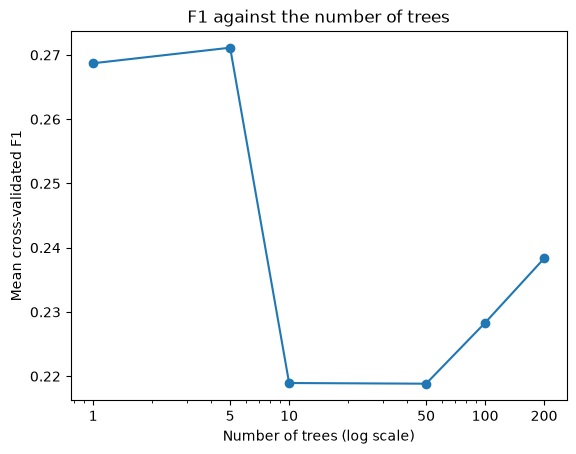

In [7]:
tree_counts = [1, 5, 10, 50, 100, 200]
size_rows = []

for n in tree_counts:
    model = RandomForestClassifier(n_estimators=n, max_features="sqrt",
                                   random_state=RANDOM_STATE, n_jobs=-1)
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=metrics)
    size_rows.append({"Trees": n, **{m.capitalize(): s[f"test_{m}"].mean() for m in metrics}})

size_results = pd.DataFrame(size_rows).set_index("Trees")
display(size_results.round(3))

plt.plot(tree_counts, size_results["F1"], marker="o")
plt.xscale("log")
plt.xticks(tree_counts, tree_counts)
plt.xlabel("Number of trees (log scale)")
plt.ylabel("Mean cross-validated F1")
plt.title("F1 against the number of trees")
plt.show()

## **Explanation**

- **Accuracy and precision rise with more trees and then level off**, as in the Week 8 example: accuracy goes from 0.757 with one tree to 0.823 with ten and 0.830 with 200; precision from 0.27 to 0.47.
- **Recall falls**, from 0.27 with one tree to about 0.15 with ten or more.
- **F1 therefore does not rise.** It is highest with 1 or 5 trees (0.27), dips to 0.22, and comes back to 0.24 at 200. This is different from the lecturer's dataset, where F1 climbed from 0.68 to 0.81.

**Why the pattern differs here**
- A single fully grown tree flags a lot of adolescents, many of them wrongly. That gives it more catches (higher recall) but many false alarms (accuracy 0.757, well below the 0.833 baseline).
- When many trees vote, an adolescent is only flagged if most trees agree. With weak features and only 1 in 6 adolescents above the threshold, the majority rarely agrees on "depressed", so the forest flags fewer people: fewer false alarms, but also fewer catches.
- So adding trees makes the forest more accurate and more cautious, rather than better at finding cases.

**How many trees?** The table is flat from about 50 trees onwards; differences between 50, 100 and 200 are noise from the folds. Around 100 trees would be enough, and 200 is a safe choice that costs only extra computing time.

---
## Step 8. Which features does the forest rely on?

A forest of 200 trees cannot be read like the single tree in `decision_tree.ipynb`. **Feature importance** gives a summary: how much each feature reduced impurity across all splits in all trees, scaled to sum to 1.

avg_sleep_hours             0.217
midsleep_weekend_hours      0.191
social_jetlag_hours         0.189
sleep_quality_index         0.172
est_leisure_screen_hours    0.098
screen_time_index           0.094
sex_binary                  0.040
dtype: float64


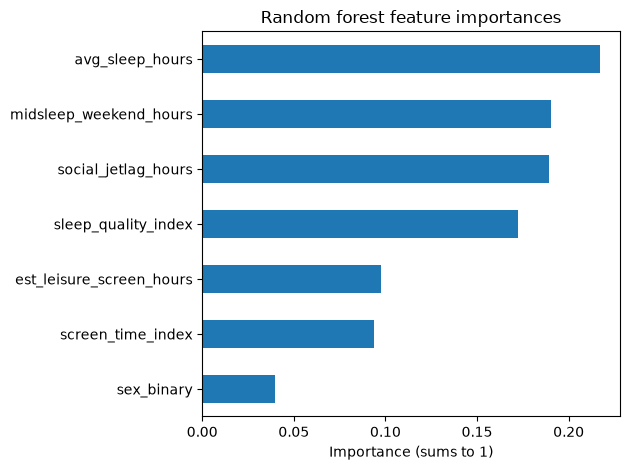

In [8]:
importances = pd.Series(forest.feature_importances_, index=feature_cols).sort_values()
print(importances.sort_values(ascending=False).round(3))

importances.plot.barh()
plt.xlabel("Importance (sums to 1)")
plt.title("Random forest feature importances")
plt.tight_layout()
plt.show()

## **Explanation**

- **The four sleep features carry most of the importance:** average sleep hours (0.22), weekend midsleep (0.19), social jetlag (0.19) and sleep quality (0.17), together about 0.77.
- **The two screen-time features are lower** (about 0.10 and 0.09), which fits the earlier models, where screen time added little.
- **`sex_binary` is lowest (0.04)**, even though it was the second question in the depth-3 tree and had the largest coefficient in the logistic regression.

**Why these importances need care**
- **They favour features with many different values.** A fully grown tree can split on hours of sleep again and again at different thresholds, and every split adds to that feature's importance. `sex_binary` has only two values, so it can be used once per branch. Its low score reflects how the measure works, not that gender is unrelated to depression in this data.
- **Correlated features share importance.** The sleep-timing measures are related to each other, so their importance is divided between them.
- **Importance is not causation.** It describes what the model uses to make predictions, not what causes adolescents to cross the threshold.

For the research question, the more trustworthy reading comes from combining the models: sleep measures matter most in every model, and gender matters in the logistic regression and the single tree.

---
## Step 9. Final evaluation on the test set

The test set is now used, once. The forest was already trained on the full training set in Step 4.

Test baseline (always 'not depressed'): 0.848
Accuracy:  0.835
Precision: 0.397
Recall:    0.171  -> caught 25 of 146 real cases
F1:        0.239
Flagged as depressed: 63


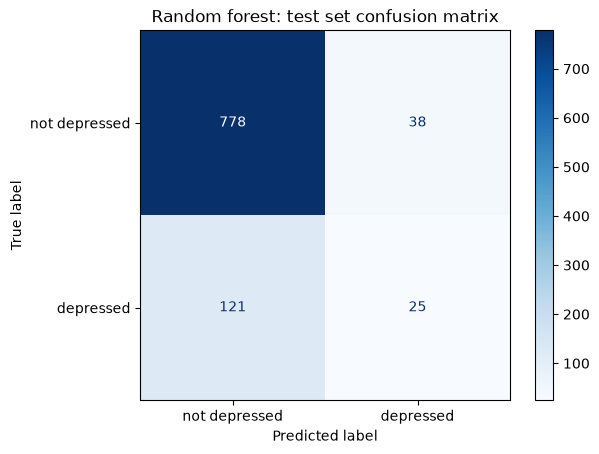

In [9]:
test_pred = forest.predict(X_test)

print(f"Test baseline (always 'not depressed'): {baseline_acc:.3f}")
print(f"Accuracy:  {accuracy_score(y_test, test_pred):.3f}")
print(f"Precision: {precision_score(y_test, test_pred):.3f}")
print(f"Recall:    {recall_score(y_test, test_pred):.3f}  "
      f"-> caught {int(((test_pred == 1) & (y_test == 1)).sum())} of {int(y_test.sum())} real cases")
print(f"F1:        {f1_score(y_test, test_pred):.3f}")
print(f"Flagged as depressed: {int(test_pred.sum())}")

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["not depressed", "depressed"], cmap="Blues"
)
plt.title("Random forest: test set confusion matrix")
plt.show()

## **Explanation**

- **Confusion matrix:** 778 true negatives, 38 false positives, 121 false negatives, 25 true positives.
- **Accuracy 0.835**, below the baseline of 0.848.
- **Precision 0.40:** 25 of the 63 adolescents flagged are real cases.
- **Recall 0.17:** 25 of the 146 real cases are caught; 121 are missed.
- The test results are close to the cross-validation results in Step 6 (accuracy 0.830, recall 0.16), so cross-validation gave an honest forecast.

**Compared with the other models on the same 962 adolescents**

| | Accuracy | Precision | Recall | Flagged | Real cases caught (of 146) |
|---|---|---|---|---|---|
| Baseline (always "not depressed") | 0.848 | n/a | 0.000 | 0 | 0 |
| Logistic regression | 0.849 | 0.511 | 0.158 | 45 | 23 |
| KNN (k = 5) | 0.828 | 0.362 | 0.171 | 69 | 25 |
| Decision tree (depth 3) | 0.846 | 0.438 | 0.048 | 16 | 7 |
| **Random forest (200 trees)** | 0.835 | 0.397 | 0.171 | 63 | 25 |

- The forest clearly improves on the single depth-3 tree for recall (25 cases caught against 7).
- It performs about the same as KNN, and catches two more cases than logistic regression at the cost of 16 more false alarms.
- No model beats the baseline on accuracy by more than one adolescent.

---
## Step 10. Save results for the comparison notebook

The forest's test-set predictions are saved in the same format as the other model notebooks, so they can be added to `model_comparison.ipynb`.

In [10]:
import os
os.makedirs("../results", exist_ok=True)

pd.DataFrame({
    "actual": y_test.values,
    "predicted": test_pred,
    "prob_depressed": forest.predict_proba(X_test)[:, 1],
}, index=y_test.index).to_csv("../results/forest_predictions.csv", index_label="row")

print("Saved ../results/forest_predictions.csv")

Saved ../results/forest_predictions.csv


---
## Summary of findings

- A **random forest** trains many trees, each on a bootstrap sample and with a random subset of features at each split, and combines them by voting.
- **The trees disagree** on almost a third of the training adolescents. Averaging them **reduces variance**: the forest's cross-validated scores are far more stable than the single depth-3 tree's (F1 SD 0.042 against 0.125).
- **Training accuracy of 1.000 is not a fair measure.** Cross-validated accuracy is 0.830, about the same as the baseline.
- **The forest is not a better classifier for this question.** It catches 25 of 146 real cases in the test set (recall 0.17), similar to KNN and logistic regression. Reducing variance does not help when the limit is how little the features separate the two groups.
- **More trees made the forest more accurate but more cautious**, so F1 did not rise as it did in the Week 8 example.
- **Feature importances** point to the sleep measures, in line with the earlier models, but they understate `sex_binary` because it has only two values, and they do not show causation.
- A forest is **less interpretable** than one tree: the depth-3 tree could be read as a handful of if-then rules, while 200 deep trees can only be summarised.

**Key message (Week 8):** cross-validation is used to evaluate and compare settings, and the test set is kept for one final check. An ensemble improves stability; it does not replace informative features.